<a href="https://colab.research.google.com/github/PyGhosh/Grp_CH4124/blob/main/Group-A/Home-Assignment-4/230122020_HA_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


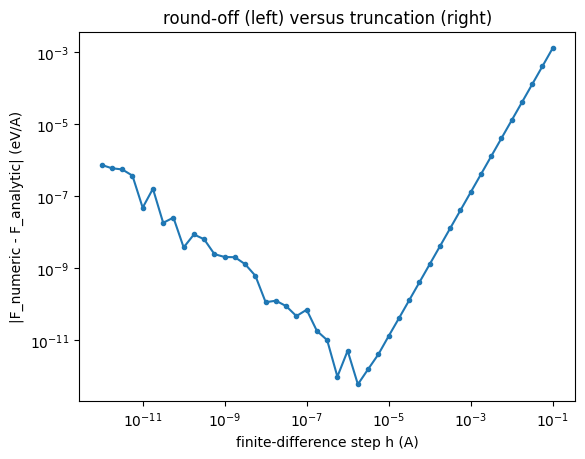

In [1]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

**Answer.** The central-difference optimum is about $1.8\times10^{-6}$ Å in this scan, which is close to the estimate $\varepsilon_{\rm mach}^{1/3}r$ (a few $10^{-6}$ Å for a length scale of a few Å). With the forward difference, the optimum is around $10^{-8}$ Å here. Its minimum error is also larger: roughly $5.5\times10^{-10}$ eV/Å, compared with about $6.0\times10^{-13}$ eV/Å for the central difference. The forward difference has a truncation error proportional to $h$, rather than $h^2$, so it generally gives a less accurate derivative for a comparable step size.


---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


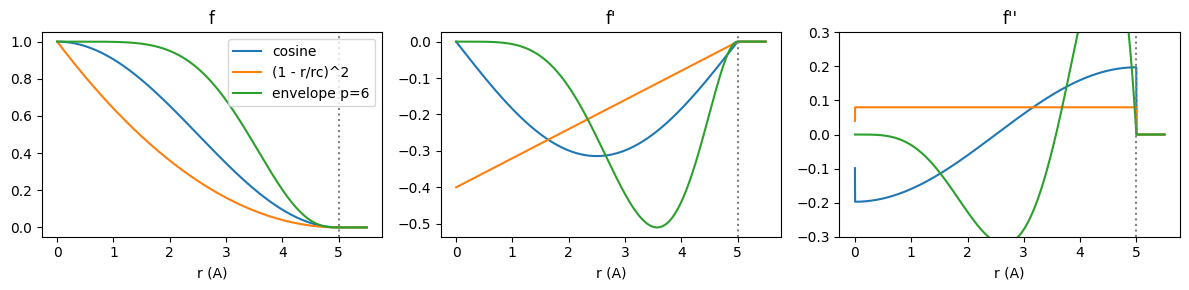

In [2]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

**Answer.** From least to most smooth at $r_c$: the cosine and $(1-r/r_c)^2$ cutoffs are tied in value and slope continuity, while the $p=6$ polynomial envelope is smoother because its value, slope, and curvature all go continuously to zero at the cutoff. For the cosine and quadratic forms, the value and first derivative match the zero function outside the cutoff, but the second derivative jumps. A curvature jump is especially noticeable when calculating phonon frequencies, because those depend on the Hessian (second derivatives of the energy). Energy conservation in molecular dynamics is usually less directly affected as long as the force remains continuous, although numerical integration can still be sensitive to reduced smoothness.


---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


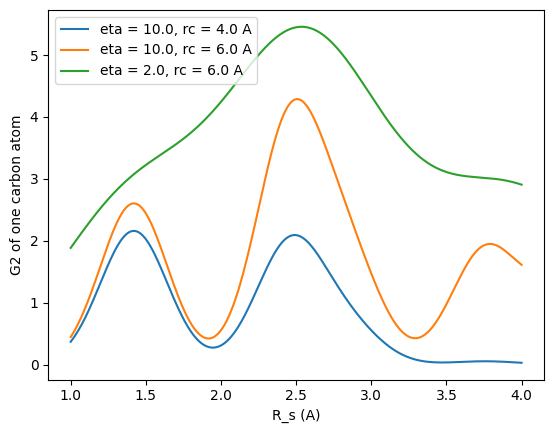

In [3]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

**Answer.** Stretching the lattice by 2% shifts the neighbour distances outward, so the peaks in $G^2(R_s)$ also shift toward larger $R_s$. The largest difference is around the second-neighbour shell, near $R_s\approx2.2$–$2.3$ Å for the parameters shown; the exact size depends on $\eta$ and the cutoff radius. With a larger $\eta$, each Gaussian is narrower, so even a small change in neighbour distance can produce a pronounced change in the fingerprint. This is how the descriptor captures local strain.


---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

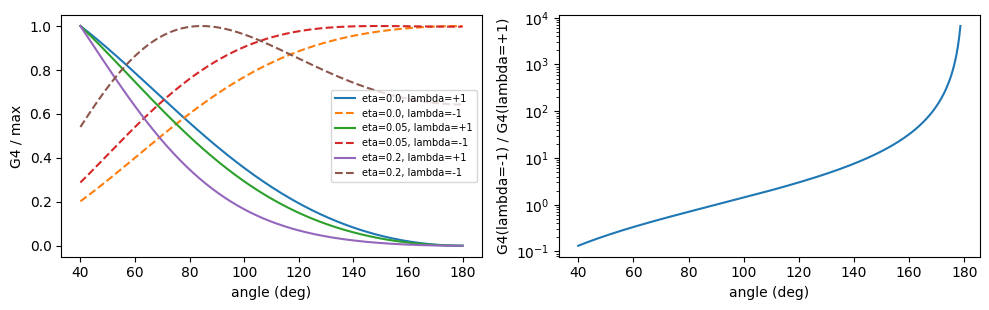

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

**Answer.** Since $r_{jk}=2b\sin(\theta/2)$, the distance $r_{jk}$ is longest at $180^\circ$ and shorter at smaller angles. The factor $e^{-\eta r_{jk}^2}$ therefore suppresses large angles more strongly as $\eta$ increases, shifting the $\lambda=-1$ peak away from $180^\circ$ toward a smaller angle (around $85^\circ$ for the stated setting). The ratio does not depend on $\eta$ because the radial exponential and cutoff factors are identical for both values of $\lambda$ and cancel when the two $G^4$ expressions are divided. For $\zeta=1$, the remaining angular ratio is $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.
